# Ejercicio 6 Distribuciones de probabilidad y sus momentos estadísticos

En este ejercicio se hizo el cálculo de la media, desviasión estándar, varianza, asimetría y kurtosis, después se graficó la distribución de probabilidad, de distribuciones normales, uniformes, exponenciales además de notar cual se ajusta mejor a la función teórica

In [129]:
import numpy as np 
import matplotlib.pyplot as plt
from scipy.linalg import sqrtm


Generamos 10000 números aleatorios con distribución normal, uniforme, y exponencial. 

In [130]:
numeros = 10000
d_normal = np.random.normal(0, 1, numeros)
d_uniforme = np.random.uniform(0, 1, numeros)
d_exponencial = np.random.exponential(scale=1, size=numeros)

Hacemos el cálculo de media, desviasión estándar, varianza, asimetría. 

In [131]:
distribucion_aleatorios = [d_normal, d_uniforme,d_exponencial ] # Juntamos los datos en un solo arreglo 
# Guardamos los datos en listas 
media = [[], [], []] 
desviasion_estandar = [[], [], []]
varianza = [[], [], []]
asimetria = [[], [], []]
kurtosis = [[], [], []]


In [132]:
# Ejecutar solo una vez 
for i in range(3):
    media[i].append(np.mean(distribucion_aleatorios[i]))
    desviasion_estandar[i].append(np.std(distribucion_aleatorios[i]))
    varianza[i].append(np.var(distribucion_aleatorios[i]))


In [133]:
print(media)
print(desviasion_estandar)
print(varianza)

[[np.float64(-0.018215590672241093)], [np.float64(0.49951871246007495)], [np.float64(1.0090122177840644)]]
[[np.float64(1.0011906474339514)], [np.float64(0.2883502774972503)], [np.float64(0.9897630262436924)]]
[[np.float64(1.0023827125092146)], [np.float64(0.08314588253274126)], [np.float64(0.9796308481190721)]]


In [134]:
# Vamos a calcular la asimetría 

for i in range(3):
    suma_acumulada = 0 
    for j in distribucion_aleatorios[i]:
        suma_acumulada += (j-media[i][0])**3
    gamma_1 = (1/(numeros * (desviasion_estandar[i][0]**3))) * suma_acumulada
    asimetria[i].append(gamma_1)


In [141]:
asimetria

[[np.float64(-0.02956480298590743)],
 [np.float64(0.006098617328716567)],
 [np.float64(1.9033662209633506)]]

Para la Kurtosis vamos a usar la definición que aparece en internet 

In [135]:
for i in range(3):
    suma_acumulada = 0 
    for j in distribucion_aleatorios[i]:
        suma_acumulada += (j-media[i][0])**4
    gamma_1 = (1/(numeros * (desviasion_estandar[i][0]**4))) * suma_acumulada
    kurtosis[i].append(gamma_1)

In [140]:
kurtosis

[[np.float64(3.012007619451888)],
 [np.float64(1.8052054105953506)],
 [np.float64(8.207804150351583)]]

Comentario: 
Realmente analizar los valores de manera cuantitativa es díficil, ya que tenemos 10000 datos generados, así que, comparar si la desviasión estandár es grande pues no es tan efectivo si lo hacemos con los puros resultados. 
Lo que esperariamos sería normal: asimetría \(\approx 0\), uniforme: asimetría \(\approx 0\), exponencial: asimetría positiva, teóricamente \(2\).

Vamos a realizar las gráficas y vamos a comparar con las funciones que las generan 

In [136]:
# Normal
x_normal = np.linspace(-4, 4, 1000)
f_normal = (1 / np.sqrt(2*np.pi)) * np.exp(-(x_normal**2)/2)

# Uniforme
x_uniforme = np.linspace(0, 1, 1000)
f_uniforme = np.ones_like(x_uniforme)

# Exponencial
x_exponencial = np.linspace(0, 8, 1000)
f_exponencial = np.exp(-x_exponencial)

In [137]:
Valores = [x_normal, x_uniforme, x_exponencial]
funciones = [f_normal, f_uniforme, f_exponencial]

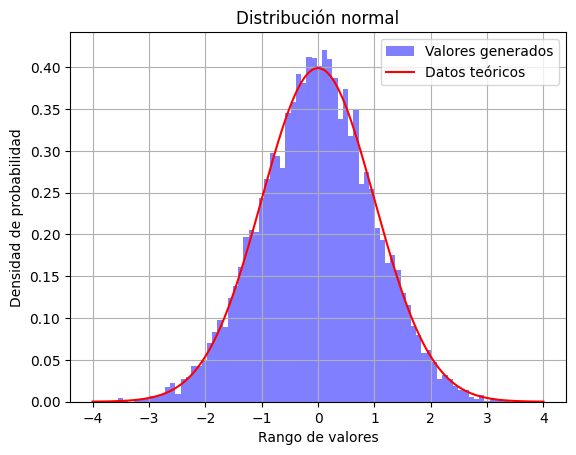

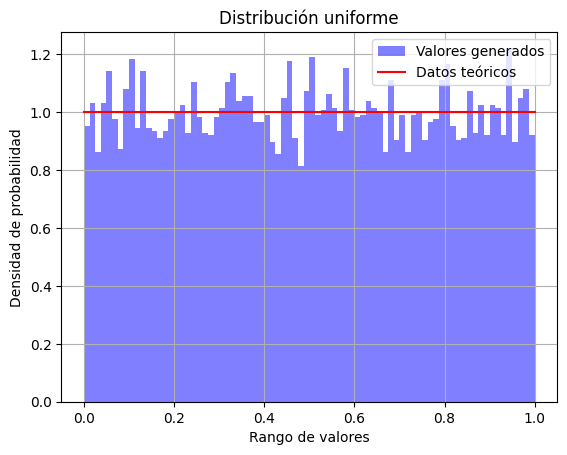

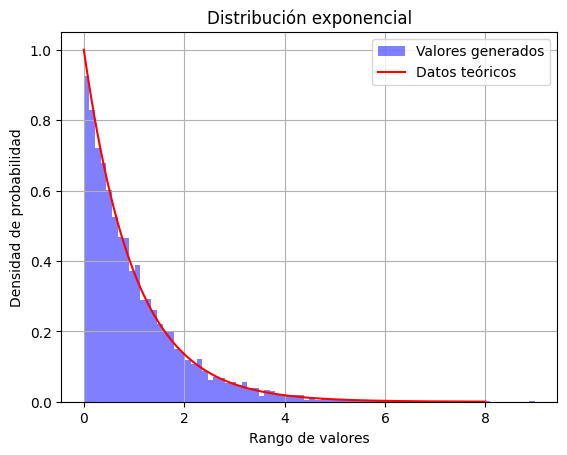

In [142]:
titulo = ["normal", "uniforme", "exponencial"]
for i in range(3):
    plt.hist(distribucion_aleatorios[i],  bins=80, density=True, alpha=0.5, color = "blue", label = "Valores generados")
    plt.plot(Valores[i], funciones[i], color = "red", label = "Datos teóricos" )
    plt.legend(loc = "best")
    plt.grid()
    plt.title(f"Distribución {titulo[i]}")
    plt.xlabel("Rango de valores")
    plt.ylabel("Densidad de probabilidad")
    plt.show()

Notamos que para los 10000 valores generados los que más se ajustan es la distribución exponecial, a pesar de que se probó con varios bins sigue siendo la que más se ajusta seguida de la normal, y al final la distribución uniforme es la que menos se ajusta a los datos. 